# Processing a Landsat 8/9 image

GRS processes the Level-1 (collection 2, `L1TP` / `L1GT`) products of Landsat 8 and 9 (OLI) like the
Sentinel-2 images. This notebook works on a subset of a Landsat 9 scene over the Rhône delta and the
Berre lagoon (France), acquired on 2022-11-20:

- the Level-1 scene read with [GRSdriver](https://github.com/Tristanovsk/GRSdriver), preview of the
  whole scene and choice of an area of interest,
- the specificities of Landsat in GRS: bands, viewing geometry, level-1 quality flags,
- the processing of the area of interest, passed to GRS as an `xarray.Dataset`,
- maps and spectra of the remote-sensing reflectance $R_{rs}$ of the delta, the lagoons and the
  Rhône plume.

## 1. Libraries

In [1]:
import os
import time
import warnings

# deprecation notices of the dependencies, not useful here
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Consolidated metadata')

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pyproj import Transformer

from osgeo import gdal
import GRSdriver
import grs

gdal.UseExceptions()

opj = os.path.join
print(f'grs:       {grs.__version__}')
print(f'GRSdriver: {GRSdriver.__version__}')

grs:       3.1.0
GRSdriver: 1.0.10


In [2]:
# settings: edit the paths to run the notebook on your own data
l1_file = '/data/satellite/landsat/LC09_L1TP_196030_20221120_20230321_02_T1'   # unzipped L1 product
cams_file = '/data/cams/world/cams_forecast_2022-11.nc'

odir = '/data/satellite/landsat/grs_tutorial'
product = opj(odir, 'LC09_L2AGRS_196030_20221120_rhone_delta.zarr')

# area of interest (longitude / latitude): Rhône delta, Camargue and Berre lagoons
aoi = gpd.GeoSeries([box(4.35, 43.25, 5.3, 43.6)], crs=4326)

resolution = 30        # m, native resolution of the OLI reflective bands
aot_resolution = 240   # m, grid of the aerosol retrieval, multiple of resolution

## 2. The Level-1 scene

A preview of the whole scene at 120 m, with the area of interest. The top-of-atmosphere reflectance
`bands` is read from the digital numbers with the calibration of the metadata file (`MTL`), and the
angles from the angle bands (`SZA`, `SAA`, `VZA`, `VAA`).

Text(0.5, 1.0, 'Landsat 9, 2022-11-20, top-of-atmosphere reflectance')

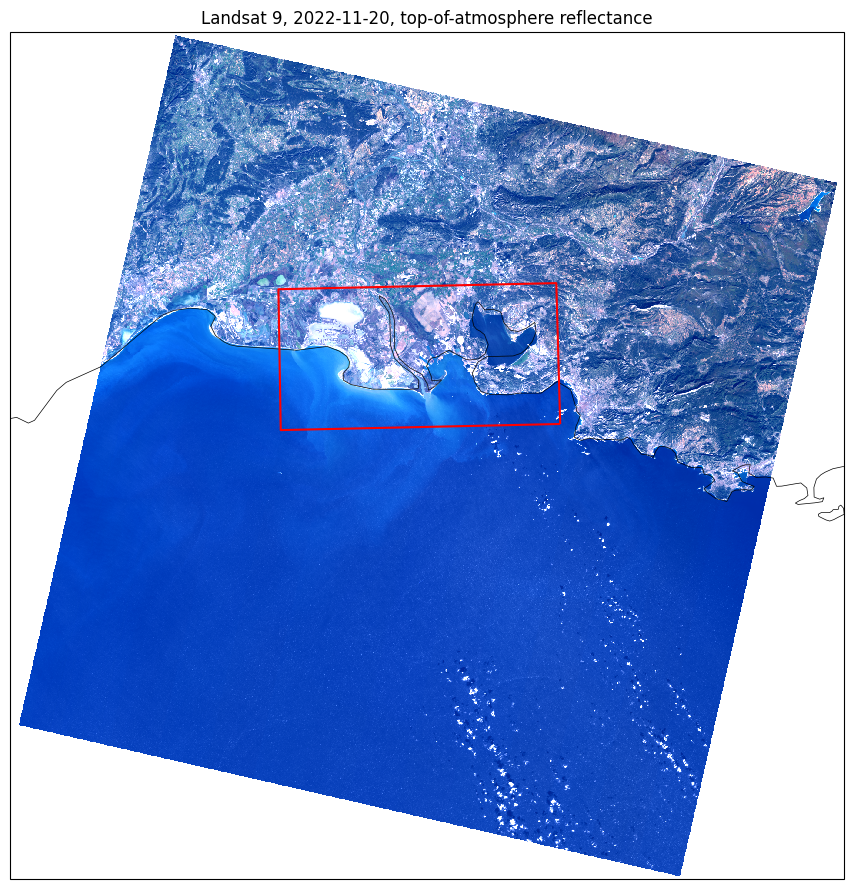

In [3]:
preview = GRSdriver.LandsatDriver(l1_file, resolution=120)
preview.load_product()
scene = preview.prod

epsg = scene.rio.crs.to_epsg()
proj = ccrs.UTM(epsg % 100, southern_hemisphere=epsg // 100 == 327)

fig, ax = plt.subplots(figsize=(11, 11), subplot_kw={'projection': proj})
scene.bands.sel(wl=[655, 561, 482], method='nearest').plot.imshow(rgb='wl', robust=True, ax=ax, transform=proj)
aoi.to_crs(epsg).boundary.plot(ax=ax, color='red', transform=proj)
ax.coastlines('10m', linewidth=0.5)
ax.set_title('Landsat 9, 2022-11-20, top-of-atmosphere reflectance')

Specificities of Landsat 8/9 in GRS:

- **bands**: the OLI bands from 443 to 2201 nm (the 865 nm band for the NIR, 1609 and 2201 nm for the
  sunglint); 1373 nm (cirrus) is used for the cloud flags only;
- **geometry**: a single viewing geometry for all the bands (on Sentinel-2, the viewing angles depend
  on the band);
- **flags**: the clouds are taken from the level-1 quality band `QA_PIXEL` (copied into `flags`, bits
  `l1_*`), instead of the s2cloudless detection of Sentinel-2.

In [4]:
pd.DataFrame({'wavelength (nm)': scene.wl.values,
              'central wavelength (nm)': np.round(scene.wl_true.values, 1) if 'wl_true' in scene else np.nan})

,wavelength (nm),central wavelength (nm)
0,443.0,442.8
1,490.0,482.3
2,560.0,560.9
3,590.0,593.9
4,665.0,654.3
5,865.0,864.6
6,1370.0,1374.1
7,1610.0,1608.3
8,2190.0,2200.9


## 3. Area of interest

The area is read at full resolution only (`subset`), with the level-1 flags (`load_mask`).

In [5]:
l1 = GRSdriver.LandsatDriver(l1_file, resolution=resolution, subset=aoi)
l1.load_mask()
l1.load_product()
print(dict(l1.prod.sizes))

{'x': 2592, 'y': 1353, 'wl': 9, 'wl_hr': 2951}


## 4. Processing

{py:meth}`~grs.grs_process.Process.execute` also takes a level-1 image already loaded as an
`xarray.Dataset` (here the subset), instead of the path of the product. The processing is lazy; the
product is computed and written by {py:meth}`~grs.grs_process.Process.write_output`.

In [6]:
t0 = time.time()
process = grs.Process()
process.execute(l1.prod,
                cams_file=cams_file,
                resolution=resolution,
                aot_resolution=aot_resolution,
                odir=product)
process.write_output()
print(f'processing: {time.time() - t0:.0f} s')
print('aerosol model:', process.l2a.l2_prod.attrs['opac_model'])

INFO:root:get CAMS auxilliary data


INFO:root:flagging from l1c data


INFO:root:OmniCloudMask processing on 677 x 1296 pixels (60 m)


/home/harmel/anaconda3/envs/py12/lib/python3.12/site-packages/omnicloudmask/cloud_mask.py:274: UserWarning: Patch size too large, reducing to 677 and overlap to 300.
  patch_overlap, patch_size = check_patch_size(


INFO:root:loading look-up tables


...

INFO:root:construct final product


INFO:root:construct l2a


INFO:root:export final product


INFO:root:export into encoded zarr


processing: 37 s
aerosol model: WASO_rh0


## 5. Results

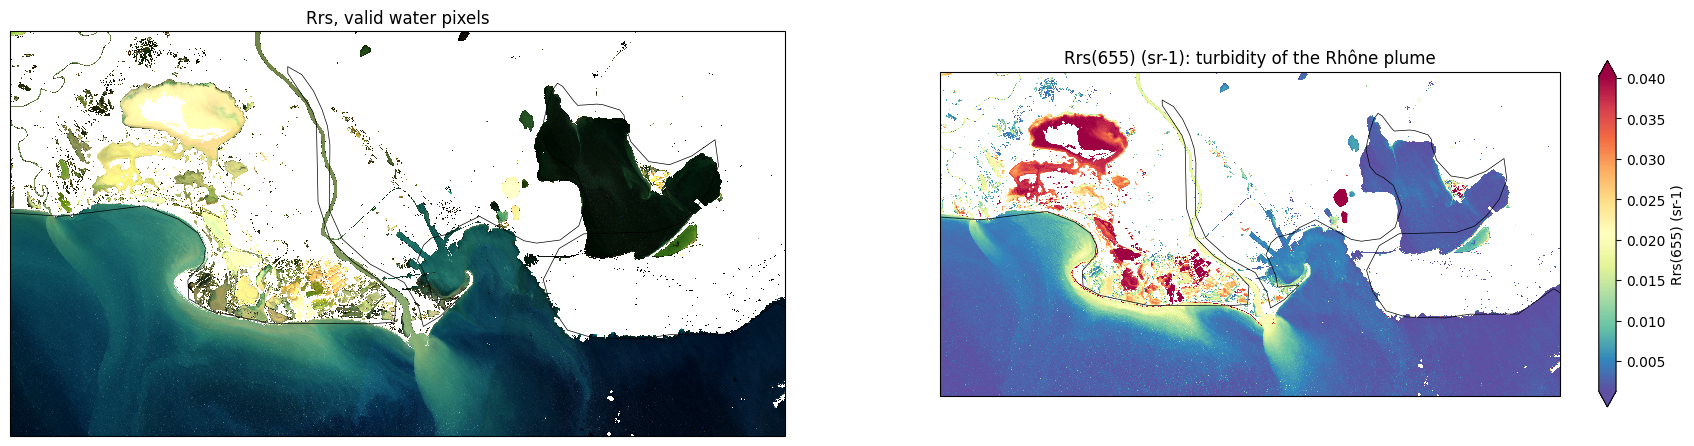

In [7]:
l2a = xr.open_zarr(product, group='0')
water = l2a.mask == 0

fig, axs = plt.subplots(1, 2, figsize=(22, 9), subplot_kw={'projection': proj})
l2a.Rrs.sel(wl=[655, 561, 482], method='nearest').where(water).plot.imshow(
    rgb='wl', robust=True, ax=axs[0], transform=proj)
axs[0].set_title('Rrs, valid water pixels')
l2a.Rrs.sel(wl=655, method='nearest').where(water).plot.imshow(
    ax=axs[1], transform=proj, cmap='Spectral_r', robust=True, cbar_kwargs={'shrink': 0.5, 'label': 'Rrs(655) (sr-1)'})
axs[1].set_title('Rrs(655) (sr-1): turbidity of the Rhône plume')
for ax in axs:
    ax.coastlines('10m', linewidth=0.5)

Aerosol optical thickness retrieved over the water pixels, and level-1 quality flags of Landsat
copied into `flags` (proportion of the area):

,name,description,proportion (%)
bit,,,
0,nodata,nodata in input image,0.00
3,water_swir_visible_index,water mask from normalized index from swir and...,54.23
4,water_red_visible_index,water mask from normalized index from nir and ...,54.49
5,thin_cirrus,"thin cirrus mask from cirrus band, threshold 0...",0.04
6,opac_cirrus,"opac cirrus mask from cirrus band, threshold 0...",0.00
7,high_swir,"high swir (bright cloud, too bright reflection...",2.18
8,surfwater_land,land mask from surfwater input file,0.00
9,surfwater_water,water mask from surfwater input file,100.00
10,surfwater_cloud_and_shadow,cloud and shadow mask from surfwater input file,0.00


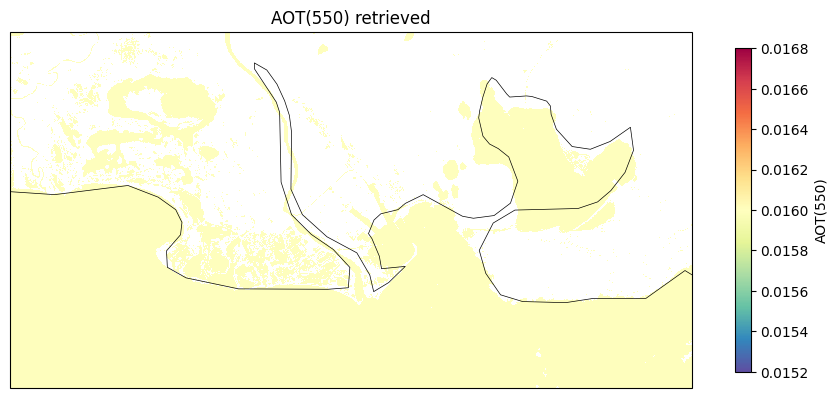

In [8]:
flags = l2a.flags.load()
names = list(flags.attrs['flag_names'])
stats = pd.DataFrame({'name': names, 'description': flags.attrs['flag_descriptions']})
stats['proportion (%)'] = [float(((flags & (1 << bit)) > 0).mean()) * 100 for bit in range(len(names))]
stats = stats[stats.name != 'None']
stats.index.name = 'bit'

fig, ax = plt.subplots(figsize=(11, 7), subplot_kw={'projection': proj})
l2a.aot550.where(water).plot.imshow(ax=ax, transform=proj, cmap='Spectral_r', robust=True,
                                    cbar_kwargs={'shrink': 0.6, 'label': 'AOT(550)'})
ax.coastlines('10m', linewidth=0.5)
ax.set_title('AOT(550) retrieved')
stats.round(2)

## 6. Spectra

$R_{rs}$ of a few water bodies (longitude, latitude):

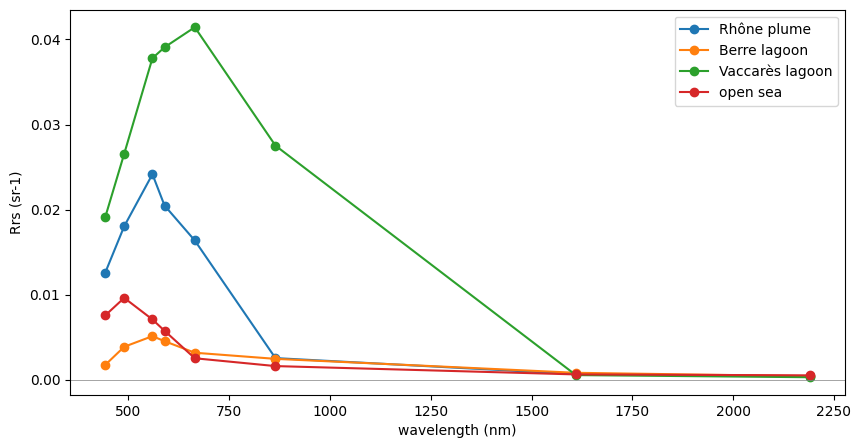

In [9]:
points = {'Rhône plume': (4.85, 43.31), 'Berre lagoon': (5.13, 43.45),
          'Vaccarès lagoon': (4.6, 43.53), 'open sea': (4.6, 43.28)}

to_utm = Transformer.from_crs(4326, epsg, always_xy=True)
fig, ax = plt.subplots(figsize=(10, 5))
for name, (lon, lat) in points.items():
    x, y = to_utm.transform(lon, lat)
    l2a.Rrs.where(water).sel(x=x, y=y, method='nearest').plot(ax=ax, marker='o', label=name)
ax.axhline(0, color='grey', lw=0.5)
ax.set(xlabel='wavelength (nm)', ylabel='Rrs (sr-1)', title='')
ax.legend()

## 7. Command line

A whole Landsat scene is processed from the terminal with the folder of the unzipped product:

```bash
grs LC09_L1TP_196030_20221120_20230321_02_T1 --cams_file cams_forecast_2022-11.nc --resolution 30
```